# 392 stocks within 10 factors

Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv
from scipy.linalg import eigh
from pandas import read_csv
from seaborn import histplot, scatterplot

Load Data

In [2]:
# find the ROOT & DATA folder.

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

Actually Load the Data

In [3]:
# ARPM's S&P 500 file has two header rows (header=[0, 1]) and dates as the index
stock_prices_table = read_csv(DATA_DIR/"db_stocks_sp.csv",
                              index_col=0, header=[0, 1], parse_dates=True)

# The first data column is skipped, as in ARPM's notebook; the remaining columns are the stocks
# n_bar
number_of_stocks = len(stock_prices_table.columns) - 1
# v: stocks x days
stock_prices = np.array(stock_prices_table.iloc[:, 1:number_of_stocks + 1].values).T

# run this to see what that skipped first column is
print(stock_prices_table.columns[:3])

Estimate the model

In [6]:
# Targets X: daily linear returns, today's price / yesterday's price - 1
# x
daily_linear_returns = stock_prices[:, 1:] / stock_prices[:, :-1] - 1

# Sample mean (column vector) and covariance of returns
# m_hat_x
mean_daily_return = np.average(daily_linear_returns, axis=1).reshape(-1, 1)
# s2_hat_x
return_covariance = np.cov(daily_linear_returns)

# Scale matrix sigma = Diag(standard deviations)  (eq. 26.b.91)
# sigma_hat
volatility_scale_matrix = np.sqrt(np.diag(return_covariance.diagonal()))
# sigma_hat^-1
inverse_volatility_scale_matrix = inv(volatility_scale_matrix)

# Rescaling the covariance by sigma^-1 on both sides gives the correlation matrix (Alert 26.b.4)
# cr_hat_x
return_correlation = inverse_volatility_scale_matrix @ return_covariance @ inverse_volatility_scale_matrix

# PCA on the correlation matrix (eq. 26.b.92); eigh returns ascending order, so reverse it
# lam_hat, e_hat
eigenvalues, eigenvectors = eigh(return_correlation)
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]

# Sign convention: flip each eigenvector so its largest entry (in absolute value) is positive
largest_entry_is_negative = np.diag(eigenvectors[np.argmax(np.abs(eigenvectors), axis=0), :]) < 0
eigenvectors[:, largest_entry_is_negative] = -eigenvectors[:, largest_entry_is_negative]

# k_bar
number_of_factors = 10

# Loadings beta = sigma * e_(1:k)  (eq. 26.b.93): how much each stock moves per unit of each factor
# beta_hat_pc, n_bar x k_bar
factor_loadings = volatility_scale_matrix @ eigenvectors[:, :number_of_factors]

# Construction matrix gamma = e_(1:k)' * sigma^-1  (eq. 26.b.94): the recipe that builds factors from returns
# gamma_hat_pc, k_bar x n_bar
factor_construction_matrix = eigenvectors[:, :number_of_factors].T @ inverse_volatility_scale_matrix

# Intercepts alpha = sample mean  (eq. 26.b.95)
# alpha_hat_pc
intercepts = mean_daily_return

stock_number = 5  # "Abbott Laboratories" in the page's example (1-based)
print('loadings of stock', stock_number, '=', factor_loadings[stock_number - 1].round(6))
print()
print('intercept of stock', stock_number, '=', intercepts[stock_number - 1].round(6))

# Factor time series z_t = gamma (x_t - m)  (eq. 26.b.96): encoder applied to every day
# z_hat_pc, k_bar x days
factor_returns = factor_construction_matrix @ (daily_linear_returns - mean_daily_return)

# Residuals = actual returns minus the model's rebuilt returns  (eq. 26.b.101)
# eps
residual_returns = daily_linear_returns - (intercepts + factor_loadings @ factor_returns)

# gamma @ beta should be the 10 x 10 identity
print('max |gamma beta - I| =', np.abs(factor_construction_matrix @ factor_loadings - np.eye(number_of_factors)).max())
print()
# Sample factor covariance should be Diag(first 10 eigenvalues)  (eq. 26.b.97)
print('max |Cov(z) - Diag(lam)| =', np.abs(np.cov(factor_returns) - np.diag(eigenvalues[:number_of_factors])).max())
print()

# r-squared as a function of the number of factors  (eq. 26.b.98)
r_squared_by_number_of_factors = np.cumsum(eigenvalues) / np.sum(eigenvalues)
plt.plot(np.arange(1, 51), r_squared_by_number_of_factors[:50], marker='.')
plt.axvline(number_of_factors, color='red', ls='--', label=f'k = {number_of_factors}')
plt.xlabel('number of factors k'); plt.ylabel('r-squared'); plt.title('How much 10 factors explain')
plt.legend()
plt.show();

loadings of stock 5 = [ 1.164e-03  3.920e-04 -9.930e-04  1.754e-03  2.860e-04 -1.150e-04
  1.255e-03 -6.650e-04 -8.020e-04 -6.000e-06]

intercept of stock 5 = [0.000616]
max |gamma beta - I| = 8.881784197001252e-16

max |Cov(z) - Diag(lam)| = 2.5579538487363607e-13



<Figure size 640x480 with 1 Axes>

2. Residual features

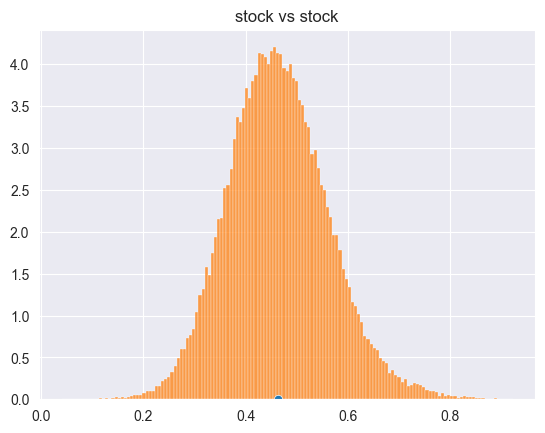

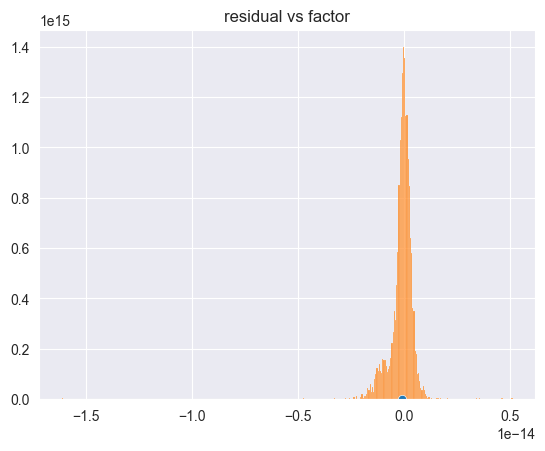

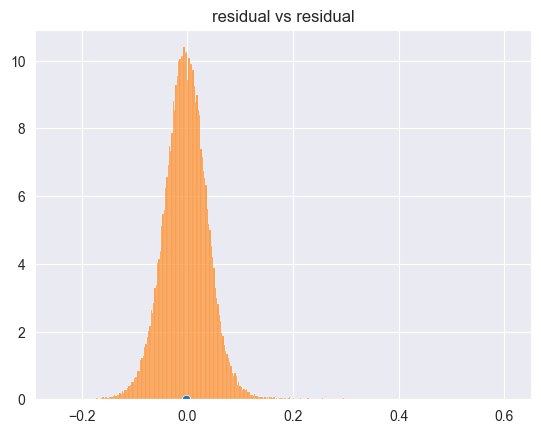

In [7]:
# Correlation matrix of residuals and factors stacked together: (n_bar + k_bar) x (n_bar + k_bar)
# cr_hat_epsz
residual_and_factor_correlation = np.corrcoef(np.vstack((residual_returns, factor_returns)))

# Each pair counted once: entries above the diagonal
upper_triangle = np.triu_indices(number_of_stocks, 1)

# cr_hat_eps (~77,000 pairs)
residual_vs_residual = residual_and_factor_correlation[:number_of_stocks, :number_of_stocks][upper_triangle]
## 392 x 10 pairs
residual_vs_factor = residual_and_factor_correlation[:number_of_stocks, number_of_stocks:].flatten()
# raw return correlations
stock_vs_stock = return_correlation[upper_triangle]

for title, correlations in [('stock vs stock', stock_vs_stock),
                            ('residual vs factor', residual_vs_factor),
                            ('residual vs residual', residual_vs_residual)]:
    # dot marks the average
    scatterplot(x=[np.average(correlations)], y=[0], zorder=2)
    histplot(correlations, stat='density').set(title=title, ylabel='')
    plt.show()

    # 1. stock vs stock - mostly +ve and ceneterd and well above 0
    # 2. residual vs factor - every value is essentially 0, around 1e-15 so the histogram is a single spike.
    # This holds in sample because the residuals live in the discarded eigenvector directions.
    # 3. residual vs residual - centered near 0 but with a real spread.  77,000 correlations that are small but
    # not zero

3. Truncation

In [9]:
# Sample covariances of residuals and of factors
# s2_hat_epsz
residual_and_factor_covariance = np.cov(np.vstack((residual_returns, factor_returns)))
# s2_hat_eps
residual_covariance = residual_and_factor_covariance[:number_of_stocks, :number_of_stocks]
# s2_hat_z
factor_covariance = np.cov(factor_returns)

# Truncated covariance (eq. 26.b.102): factor part + ONLY the diagonal of the residual covariance
# i.e. pretend the residuals are uncorrelated with each other
# s2_hat_trunc_x
truncated_return_covariance = (factor_loadings @ factor_covariance @ factor_loadings.T
                               + np.diag(np.diag(residual_covariance)))

def portfolio_volatility(weights, covariance):
    """Standard deviation of portfolio return w'X: sqrt(w' Cov w)."""
    return np.sqrt(weights.T @ covariance @ weights).item()

# Portfolio 1: equal weight across all stocks
# w_1
equal_weights = np.ones((number_of_stocks, 1)) / number_of_stocks

# Portfolio 2: long one stock, short another (weights sum to zero)
# w_2
long_short_weights = np.zeros((number_of_stocks, 1))
# 0-based row positions (you can change them)
long_stock_index, short_stock_index = 350, 363
long_short_weights[long_stock_index] = 1
long_short_weights[short_stock_index] = -1

for name, weights in [('equal-weight', equal_weights), ('long/short', long_short_weights)]:
    print(name)
    print('  truncated sd  =', round(portfolio_volatility(weights, truncated_return_covariance), 4))
    print('  historical sd =', round(portfolio_volatility(weights, return_covariance), 4))
    print()

# Why the truncation is done.
# The full residual is 392x392, with about 77,000 noisy cross-terms.
# In Industry, they often keep just the 392 residual variances on the diagonal.
# The resulting matrix is compact, always +ve definite, and has a classic "factors + idiosyncratic noise' shape

equal-weight
  truncated sd  = 0.017
  historical sd = 0.0169

long/short
  truncated sd  = 0.0317
  historical sd = 0.0207



Using the page's numbers:

Equal weights is fine.

Spread over 392 stocks, nearly all its risk is factor risk, mostly "the market".
The residual cross-terms are tiny next to that, so dropping them barely matters.

Long/Short breaks.

Being long one stock and short another cancels most of he shared factor exposure.
Whats left is mainly residual risk, and here the residual correlation between those 2 stocks matters.
In the full covariance, the -2.Cov(E350,E365) term reduces the risk because their residuals are +ve-ly correlated.
Truncation sets that term to zero, so it overstates the risk by about 50%

For a trade, the lesson is that truncated factor models are fine fro diversified long-only books,
but unreliable for hedged or pairs positions.  Thos positions live in exactly the part of the covariance the truncation throws away.

With the indices 350 and 363 you can try other pairs: 2 stocks from the same sector should show the biggest gap